# Can neural networks reproduce the Lorenz butterfly effect?

[Selz and Craig (2023)](https://doi.org/10.1029/2023GL105747) found that an AI weather model could make accurate forecasts while failing to reproduce the rapid growth of tiny initial differences. This notebook tests the same idea in the simpler Lorenz-63 system.

> **Research question.** Can a CNN and an FNO predict a Lorenz-63 trajectory from its initial condition, and do they reproduce the butterfly effect when that initial condition is changed by a tiny amount?

The training, validation and test samples all draw $x_0$ and $y_0$ independently from the range $[-15,15]$. The third initial value is fixed at $z_0=20$ so that the input has only two variables, which simplifies the learning problem and reduces computation. The numerical reference uses $\Delta t=0.01$; every fifth point is retained, giving 300 target timesteps at $\Delta t=0.05$ as Lorezn model start to diverge near 200 timesteps.

The two learned models are a convolutional neural network (CNN) and a Fourier neural operator (FNO) to compare spatially and spectral leanring. Forecast accuracy and the growth of perturbed pairs are evaluated separately because a model can score well on ordinary forecast error without reproducing sensitive dependence on initial conditions.


## 1. Reproducible Colab setup

The following cell imports the required packages, fixes random seeds and selects the available accelerator. `QUICK_RUN=True` is only for checking that the notebook executes; the reported experiment uses `False`.


In [1]:
import copy
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
from IPython.display import Markdown, display
from scipy.integrate import solve_ivp
from torch import nn
from torch.utils.data import DataLoader, TensorDataset

plt.style.use('seaborn-v0_8-whitegrid')
plt.rcParams.update({
    'figure.figsize': (10, 6),
    'figure.dpi': 200,
    'axes.titlesize': 14,
    'axes.titleweight': 'bold',
    'axes.labelsize': 12,
    'xtick.labelsize': 10,
    'ytick.labelsize': 10,
    'legend.fontsize': 9,
})

SEED = 42
QUICK_RUN = False

TRUTH_DT = 0.01
MODEL_DT = 0.05
SUBSAMPLE_FACTOR = int(round(MODEL_DT / TRUTH_DT))
FORECAST_STEPS = 60 if QUICK_RUN else 300
TRAIN_SIZE = 256 if QUICK_RUN else 2000
VALID_SIZE = 64 if QUICK_RUN else 400
TEST_SIZE = 64 if QUICK_RUN else 400
MAX_EPOCHS = 5 if QUICK_RUN else 250
PATIENCE = 3 if QUICK_RUN else 25
BATCH_SIZE = 128
Z0 = 20.0
SIGMA, RHO, BETA = 10.0, 28.0, 8.0 / 3.0

np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False

if torch.cuda.is_available():
    device = torch.device('cuda')
    accelerator_name = torch.cuda.get_device_name(0)
elif torch.backends.mps.is_available():
    device = torch.device('mps')
    accelerator_name = 'Apple Metal Performance Shaders'
else:
    device = torch.device('cpu')
    accelerator_name = 'CPU'

print(f'Using {accelerator_name}')


Using Tesla T4


## 2. Lorenz-63 and the numerical reference

The Lorenz-63 equations are

$$
\dot x=\sigma(y-x),\qquad
\dot y=x(\rho-z)-y,\qquad
\dot z=xy-\beta z.
$$
In the Lorenz-63 system, σ represents the Prandtl number quantifying the ratio of fluid viscosity to thermal diffusivity, ρ is the normalized Rayleigh number measuring the thermal driving force, and β is a geometric parameter dictated by the aspect ratio of the convection rolls.

The Lorenz function and `solve_ivp` setup are adapted from the supplied course notebook, *model_data_scrap.ipynb*. The dataset uses vectorised fourth-order Runge-Kutta (RK4) steps of $0.01$ so that many initial conditions can be integrated efficiently. “Reference” below means this numerical solution, not an exact analytical solution. A short comparison with high-accuracy `solve_ivp` checks that the RK4 implementation is accurate.


In [2]:
def lorenz63(t, state, sigma=SIGMA, rho=RHO, beta=BETA):
    x_value, y_value, z_value = state
    return [
        sigma * (y_value - x_value),
        x_value * (rho - z_value) - y_value,
        x_value * y_value - beta * z_value,
    ]


def lorenz_rhs(states):
    x_value = states[:, 0]
    y_value = states[:, 1]
    z_value = states[:, 2]
    return np.column_stack([
        SIGMA * (y_value - x_value),
        x_value * (RHO - z_value) - y_value,
        x_value * y_value - BETA * z_value,
    ])

#rk4 time stepping
def integrate_rk4(initial_states, steps, dt=TRUTH_DT, save_every=1):
    states = np.asarray(initial_states, dtype=np.float64).copy()
    if states.ndim == 1:
        states = states[None, :]
    saved = [states.copy()]
    for step in range(1, steps + 1):
        k1 = lorenz_rhs(states)
        k2 = lorenz_rhs(states + 0.5 * dt * k1)
        k3 = lorenz_rhs(states + 0.5 * dt * k2)
        k4 = lorenz_rhs(states + dt * k3)
        states = states + dt * (k1 + 2 * k2 + 2 * k3 + k4) / 6
        if not np.isfinite(states).all():
            raise FloatingPointError(f'Non-finite RK4 state at step {step}')
        if step % save_every == 0:
            saved.append(states.copy())
    return np.stack(saved, axis=1)


check_initial = np.array([0.1, 0.1, 0.1])
check_time = np.arange(0, 2.0 + TRUTH_DT / 2, TRUTH_DT)
check_scipy = solve_ivp(
    lorenz63,
    (check_time[0], check_time[-1]),
    check_initial,
    t_eval=check_time,
    method='DOP853',# DOP853 is an explicit Runge–Kutta method of order 8
    rtol=1e-11,
    atol=1e-13,
)
check_rk4 = integrate_rk4(check_initial, len(check_time) - 1)[0]
solver_check_nrmse = np.sqrt(np.mean((check_rk4 - check_scipy.y.T) ** 2)) / check_scipy.y.std()

attractor_steps = 4000
attractor = integrate_rk4(check_initial, attractor_steps)[0]
example_full = integrate_rk4(
    np.array([1.0, 1.0, Z0]),
    FORECAST_STEPS * SUBSAMPLE_FACTOR,
)[0]
example_observed = example_full[::SUBSAMPLE_FACTOR]
# compare RK4 and solve_ivp
print(f'RK4 versus solve_ivp NRMSE over t=0...2: {solver_check_nrmse:.2e}')


RK4 versus solve_ivp NRMSE over t=0...2: 9.16e-06


The next figure connects the Lorenz system to the 300-timestep learning target. Panel A shows the attractor. Panel B shows that the training target is obtained by retaining every fifth RK4 point. Panel C follows both target variables through all 300 timesteps; the repeated oscillations and lobe changes explain why a long horizon is needed before a very small initial difference can become visibly large.


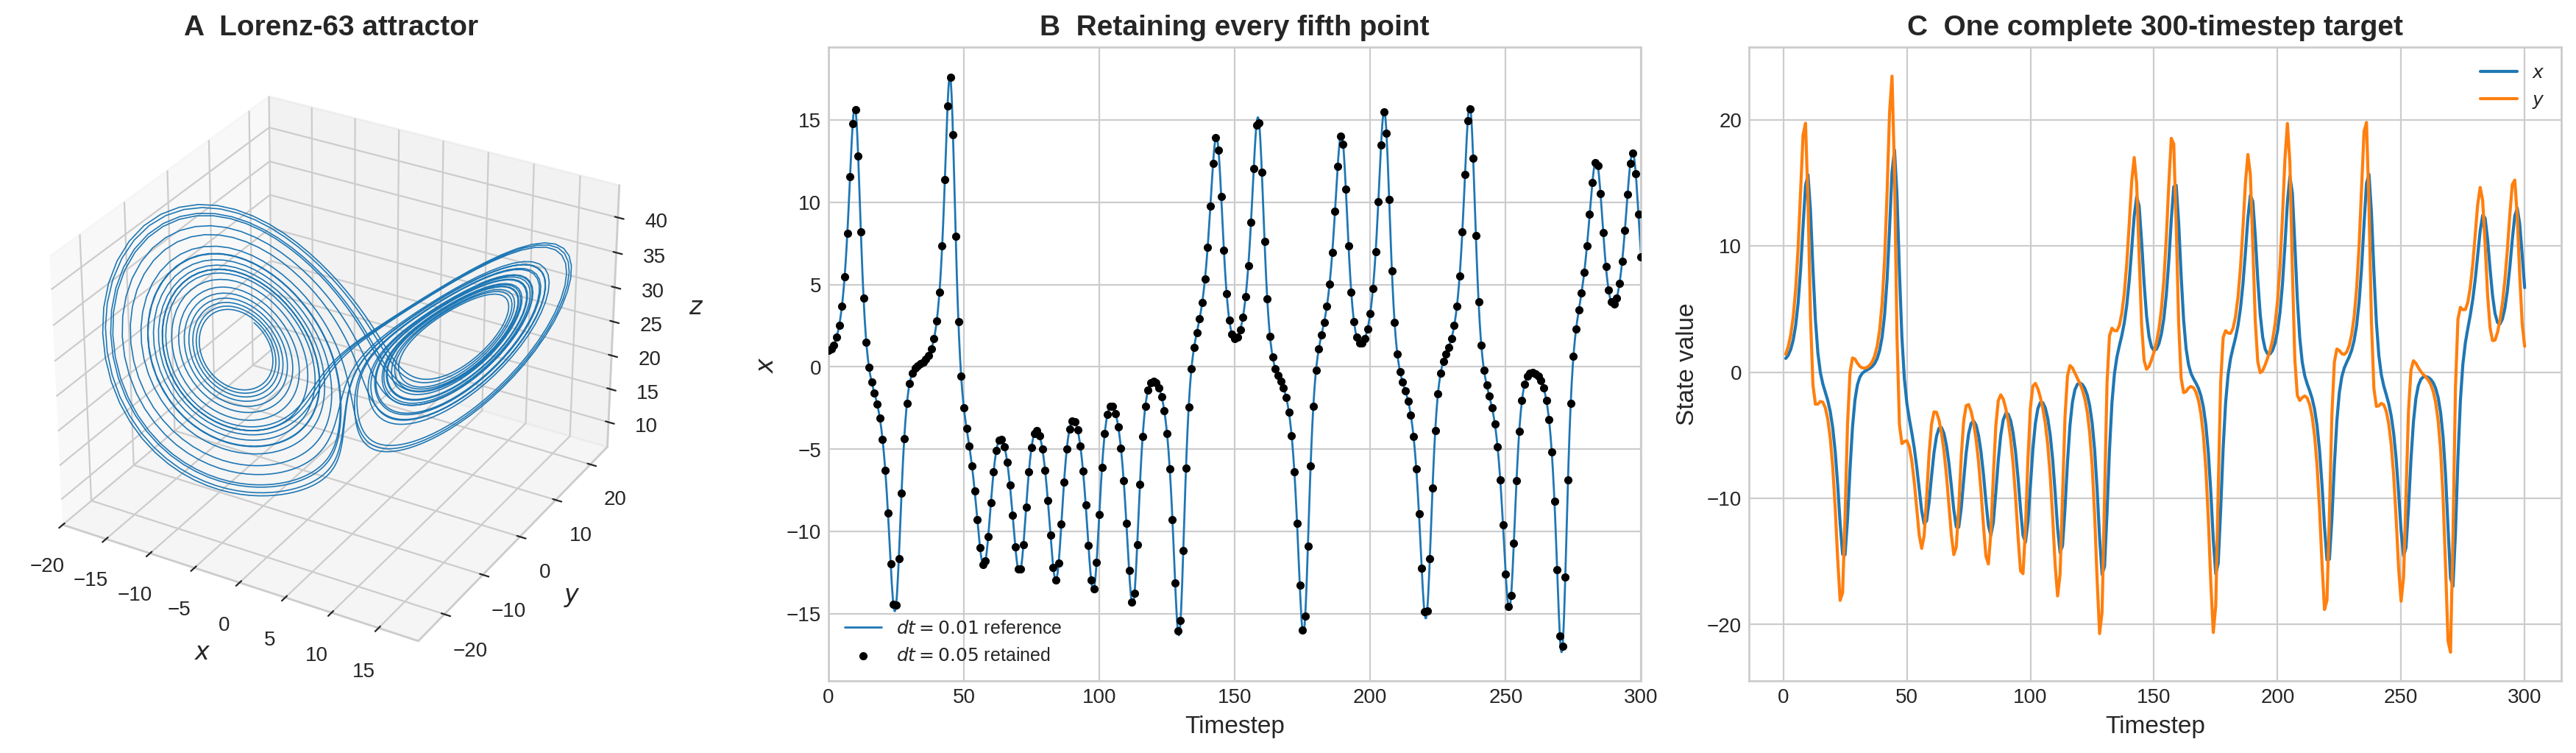

In [3]:
figure = plt.figure(figsize=(18, 5), constrained_layout=True)
axis_3d = figure.add_subplot(1, 3, 1, projection='3d')
axis_subsample = figure.add_subplot(1, 3, 2)
axis_target = figure.add_subplot(1, 3, 3)

plot_attractor = attractor[1000:]
axis_3d.plot(plot_attractor[:, 0], plot_attractor[:, 1], plot_attractor[:, 2], lw=0.6)
axis_3d.set(title='A  Lorenz-63 attractor', xlabel='$x$', ylabel='$y$', zlabel='$z$')

reference_steps = np.arange(len(example_full)) / SUBSAMPLE_FACTOR
retained_steps = np.arange(len(example_observed))
axis_subsample.plot(reference_steps, example_full[:, 0], lw=1.0, label='$dt=0.01$ reference')
axis_subsample.scatter(
    retained_steps,
    example_observed[:, 0],
    s=9, color='black', label='$dt=0.05$ retained', zorder=3,
)
axis_subsample.set(title='B  Retaining every fifth point', xlabel='Timestep', ylabel='$x$')
axis_subsample.set_xlim(0, FORECAST_STEPS)
axis_subsample.legend()

target_steps = np.arange(1, FORECAST_STEPS + 1)
axis_target.plot(target_steps, example_observed[1:, 0], label='$x$')
axis_target.plot(target_steps, example_observed[1:, 1], label='$y$')
axis_target.set(title='C  One complete 300-timestep target', xlabel='Timestep', ylabel='State value')
axis_target.legend()
plt.show()


Panel C shows repeated oscillatory cycles and switches between the two Lorenz lobes. Keeping all 300 timesteps gives a small perturbation enough time to grow and makes the butterfly-effect test visible(shown in session 7).


## 3. Independent initial conditions and 300-step targets

The dataset contains 2,000 training, 400 validation and 400 test initial conditions. In every split, both $x_0$ and $y_0$ range from -15 to 15 and $z_0=20$ is fixed. For each sample, ( $x_0$,$y_0$) is repeated across 300 positions with the changing timestep coordinate to form an input of shape (3,300), making it explicit that every predicted timestep depends on the same initial condition like mapping from ( $x_0$,$y_0$) to ($x_n$,$y_n$) directly. Training fits the weights, validation chooses the stopping point, and test data are used only for the final comparison.

Inputs and targets are standardised using training-set means and standard deviations; both models use 300-timestep mean-squared error, AdamW with learning rate `0.001`, batches of 128 and validation early stopping with patience 25.


In [4]:
def sample_initial_xy(sample_count, seed):
    rng = np.random.default_rng(seed)
    return rng.uniform(-15.0, 15.0, size=(sample_count, 2))


def generate_state_targets(initial_xy):
    initial_states = np.column_stack([
        initial_xy,
        np.full(len(initial_xy), Z0),
    ])
    reference = integrate_rk4(
        initial_states,
        FORECAST_STEPS * SUBSAMPLE_FACTOR,
        save_every=SUBSAMPLE_FACTOR,
    )
    targets = reference[:, 1:, :]
    if targets.shape != (len(initial_xy), FORECAST_STEPS, 3):
        raise RuntimeError(f'Unexpected target shape: {targets.shape}')
    return targets.astype(np.float32)


train_initial = sample_initial_xy(TRAIN_SIZE, SEED + 1)
valid_initial = sample_initial_xy(VALID_SIZE, SEED + 2)
test_initial = sample_initial_xy(TEST_SIZE, SEED + 3)

train_state_targets = generate_state_targets(train_initial)
valid_state_targets = generate_state_targets(valid_initial)
test_state_targets = generate_state_targets(test_initial)
train_targets = train_state_targets[:, :, :2]
valid_targets = valid_state_targets[:, :, :2]
test_targets = test_state_targets[:, :, :2]

split_summary = pd.DataFrame({
    'Split': ['Training', 'Validation', 'Test'],
    'Initial conditions': [TRAIN_SIZE, VALID_SIZE, TEST_SIZE],
    'Target shape per sample': [
        f'{FORECAST_STEPS} × 2', f'{FORECAST_STEPS} × 2', f'{FORECAST_STEPS} × 2'
    ],
    'Role': ['Fit weights', 'Select checkpoint and stop', 'Final evaluation only'],
})
display(split_summary)


,Split,Initial conditions,Target shape per sample,Role
0,Training,2000,300 × 2,Fit weights
1,Validation,400,300 × 2,Select checkpoint and stop
2,Test,400,300 × 2,Final evaluation only


## 4. Parameter-matched CNN and FNO models

Both models receive identical three-channel input sequences: standardised initial coordinates ($x_0$ and $y_0$) repeated across the forecasting horizon, concatenated with the normalised lead time.

The **CNN** builds upon conventional convolutional layers ([LeCun *et al.*, 1998](https://doi.org/10.1109/5.726791)) by incorporating exponentially increasing dilations ([Yu and Koltun, 2016](https://arxiv.org/abs/1511.07122)) and residual shortcuts ([He *et al.*, 2016](https://openaccess.thecvf.com/content_cvpr_2016/html/He_Deep_Residual_Learning_CVPR_2016_paper.html)). Following the Temporal Convolutional Network (TCN) architecture ([Bai *et al.*, 2018](https://arxiv.org/abs/1803.01271)), this design exponentially expands the temporal receptive field across the sequence without sacrificing resolution.

The **FNO** ([Li *et al.*, 2021](https://openreview.net/forum?id=c8P9NQVtmnO)) combines truncated Fourier convolution with pointwise mixing. Because each retained Fourier wave spans all 300 timestep positions, the FNO inherently achieves global information mixing. For its spectral branch, the FNO retains 12 modes (chosen specifically for parameter matching) from the 151 available positive frequencies ($300/2 + 1 = 151$). These low-frequency modes adequately capture smooth trajectory variations while mitigating both computational overhead and overfitting; retaining each additional mode would add approximately 2,048 real parameters.

To ensure a fair comparison, the models are strictly constrained by their real degrees of freedom, achieving a total parameter count gap of less than 5%.

In [5]:
input_mean = train_initial.mean(axis=0).astype(np.float32)
input_std = train_initial.std(axis=0).astype(np.float32)
target_mean = train_targets.mean(axis=(0, 1)).astype(np.float32)
target_std = train_targets.std(axis=(0, 1)).astype(np.float32)


def standardize_inputs(values):
    return ((values - input_mean) / input_std).astype(np.float32)


def standardize_targets(values):
    return ((values - target_mean) / target_std).astype(np.float32)


def restore_targets(values):
    return values * target_std + target_mean


train_input_standard = standardize_inputs(train_initial)
valid_input_standard = standardize_inputs(valid_initial)
test_input_standard = standardize_inputs(test_initial)
train_target_standard = standardize_targets(train_targets)
valid_target_standard = standardize_targets(valid_targets)
test_target_standard = standardize_targets(test_targets)


def make_loader(inputs, targets, shuffle, seed):
    dataset = TensorDataset(torch.from_numpy(inputs), torch.from_numpy(targets))
    generator = torch.Generator().manual_seed(seed)
    return DataLoader(
        dataset,
        batch_size=BATCH_SIZE,
        shuffle=shuffle,
        generator=generator if shuffle else None,
        num_workers=0,
    )


def trajectory_features(initial_xy):
    batch_size = initial_xy.shape[0]
    context = initial_xy[:, :, None].expand(-1, -1, FORECAST_STEPS)
    lead = torch.linspace(0, 1, FORECAST_STEPS, device=initial_xy.device)
    lead = lead.reshape(1, 1, -1).expand(batch_size, -1, -1)
    return torch.cat([context, lead], dim=1)

# CNN block
class ResidualDilatedBlock(nn.Module):
    def __init__(self, width, dilation):
        super().__init__()
        self.network = nn.Sequential(
            nn.Conv1d(width, width, kernel_size=3, padding=dilation, dilation=dilation),
            nn.GELU(),
            nn.Conv1d(width, width, kernel_size=3, padding=dilation, dilation=dilation),
        )

    def forward(self, values):
        return torch.nn.functional.gelu(values + self.network(values))


class TrajectoryCNN(nn.Module):
    def __init__(self, width=32):
        super().__init__()
        self.lift = nn.Conv1d(3, width, kernel_size=1)
        self.blocks = nn.ModuleList([
            ResidualDilatedBlock(width, dilation) for dilation in (1, 2, 4, 8)
        ])
        self.project = nn.Conv1d(width, 2, kernel_size=1)

    def forward(self, initial_xy):
        values = self.lift(trajectory_features(initial_xy))
        for block in self.blocks:
            values = block(values)
        return self.project(values).transpose(1, 2)

# FNO cnn block
class SpectralConv1d(nn.Module):
    def __init__(self, width, modes):
        super().__init__()
        self.modes = modes
        scale = 1 / width
        weights = scale * torch.randn(width, width, modes, dtype=torch.cfloat)
        self.weights = nn.Parameter(weights)

    def forward(self, values):
        spectrum = torch.fft.rfft(values, dim=-1)
        retained_modes = min(self.modes, spectrum.shape[-1])
        transformed = torch.zeros_like(spectrum)
        transformed[:, :, :retained_modes] = torch.einsum(
            'bim,iom->bom',
            spectrum[:, :, :retained_modes],
            self.weights[:, :, :retained_modes],
        )
        return torch.fft.irfft(transformed, n=values.shape[-1], dim=-1)


class TrajectoryFNO(nn.Module):
    def __init__(self, width=16, modes=12, layers=4):
        super().__init__()
        self.lift = nn.Conv1d(3, width, kernel_size=1)
        self.spectral_layers = nn.ModuleList([
            SpectralConv1d(width, modes) for _ in range(layers)
        ])
        self.pointwise_layers = nn.ModuleList([
            nn.Conv1d(width, width, kernel_size=1) for _ in range(layers)
        ])
        self.project = nn.Sequential(
            nn.Conv1d(width, width, kernel_size=1),
            nn.GELU(),
            nn.Conv1d(width, 2, kernel_size=1),
        )

    def forward(self, initial_xy):
        values = self.lift(trajectory_features(initial_xy))
        for spectral, pointwise in zip(self.spectral_layers, self.pointwise_layers):
            values = torch.nn.functional.gelu(spectral(values) + pointwise(values))
        return self.project(values).transpose(1, 2)

# for fair model parameter comparison
def real_parameter_count(model):
    return sum(
        parameter.numel() * (2 if parameter.is_complex() else 1)
        for parameter in model.parameters()
    )


## 5. Training and parameter check

The CNN uses width 32 with dilations 1, 2, 4 and 8. The FNO uses width 16, four spectral layers and 12 Fourier modes. These settings give similar trainable sizes, so the comparison is not mainly caused by one model having more parameters. The code prints the two sizes and then shows only the validation learning curves used for early stopping.


CNN parameters: 25,026
FNO parameters: 26,034
Parameter difference: 3.87%
CNN best validation NRMSE: 0.9052 at epoch 229
FNO best validation NRMSE: 0.9079 at epoch 230


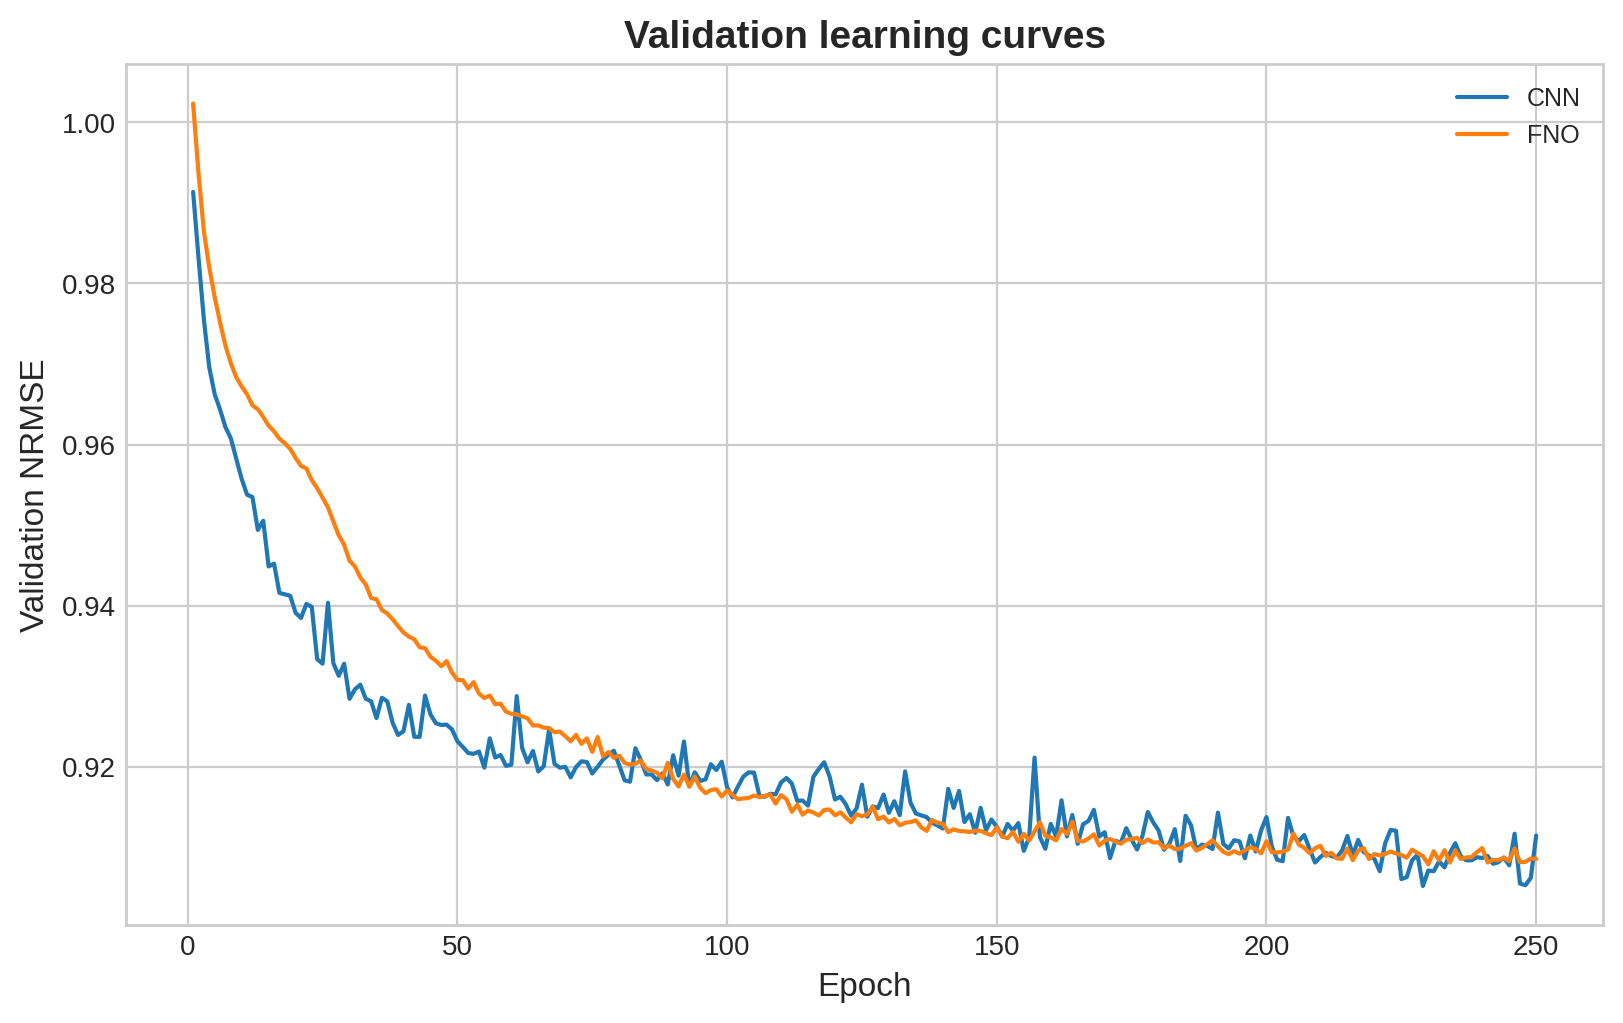

In [6]:
# training setup
valid_loader = make_loader(
    valid_input_standard, valid_target_standard, shuffle=False, seed=SEED
)


def evaluate_loss(model, loader):
    model.eval()
    total_squared_error = 0.0
    total_values = 0
    with torch.no_grad():
        for inputs, targets in loader:
            inputs = inputs.to(device)
            targets = targets.to(device)
            predictions = model(inputs)
            if not torch.isfinite(predictions).all():
                raise FloatingPointError('Non-finite validation prediction')
            total_squared_error += torch.nn.functional.mse_loss(
                predictions, targets, reduction='sum'
            ).item()
            total_values += targets.numel()
    return total_squared_error / total_values


def fit_model(constructor, seed):
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)
    model = constructor()
    model = model.to(device)
    optimiser = torch.optim.AdamW(model.parameters(), lr=1e-3, weight_decay=1e-5)
    train_loader = make_loader(
        train_input_standard, train_target_standard, shuffle=True, seed=seed
    )
    history = []
    best_loss = np.inf
    best_state = None
    stale_epochs = 0
    for epoch in range(1, MAX_EPOCHS + 1):
        model.train()
        training_squared_error = 0.0
        training_values = 0
        for inputs, targets in train_loader:
            inputs = inputs.to(device)
            targets = targets.to(device)
            optimiser.zero_grad()
            predictions = model(inputs)
            loss = torch.nn.functional.mse_loss(predictions, targets)
            if not torch.isfinite(loss):
                raise FloatingPointError('Non-finite training loss')
            loss.backward()
            torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)
            optimiser.step()
            training_squared_error += loss.item() * targets.numel()
            training_values += targets.numel()
        validation_mse = evaluate_loss(model, valid_loader)
        training_mse = training_squared_error / training_values
        history.append({
            'Epoch': epoch,
            'Training NRMSE': np.sqrt(training_mse),
            'Validation NRMSE': np.sqrt(validation_mse),
        })
        if validation_mse < best_loss - 1e-7:
            best_loss = validation_mse
            best_state = copy.deepcopy(model.state_dict())
            stale_epochs = 0
        else:
            stale_epochs += 1
            if stale_epochs >= PATIENCE:
                break
    model.load_state_dict(best_state)
    return model, pd.DataFrame(history), np.sqrt(best_loss)


model_specs = [
    ('CNN', 'width 32, dilations 1/2/4/8', lambda: TrajectoryCNN(width=32)),
    ('FNO', 'width 16, 12 modes, 4 layers', lambda: TrajectoryFNO(width=16, modes=12, layers=4)),
]

parameter_budget = {
    family: real_parameter_count(constructor())
    for family, _, constructor in model_specs
}
parameter_gap = abs(parameter_budget['CNN'] - parameter_budget['FNO']) / max(parameter_budget.values())
if parameter_gap > 0.05:
    raise RuntimeError(f'CNN/FNO real-parameter gap is {parameter_gap:.1%}, above 5%')

trained_models = {}
training_histories = {}
model_rows = []
for family, architecture, constructor in model_specs:
    model, history, validation_nrmse = fit_model(
        constructor, SEED
    )
    trained_models[family] = model
    training_histories[family] = history
    model_rows.append({
        'Model': family,
        'Architecture': architecture,
        'Real trainable parameters': parameter_budget[family],
        'Best epoch': int(history.loc[history['Validation NRMSE'].idxmin(), 'Epoch']),
        'Validation NRMSE': validation_nrmse,
    })

model_results = pd.DataFrame(model_rows)
print(f"CNN parameters: {parameter_budget['CNN']:,}")
print(f"FNO parameters: {parameter_budget['FNO']:,}")
print(f"Parameter difference: {parameter_gap:.2%}")
for row in model_rows:
    print(f"{row['Model']} best validation NRMSE: {row['Validation NRMSE']:.4f} at epoch {row['Best epoch']}")

figure, axis = plt.subplots(figsize=(8, 5), constrained_layout=True)
for family, history in training_histories.items():
    axis.plot(history['Epoch'], history['Validation NRMSE'], label=family)
axis.set(title='Validation learning curves', xlabel='Epoch', ylabel='Validation NRMSE')
axis.legend()
plt.show()


## 6. Test performance on unseen initial conditions

The frozen CNN and FNO are evaluated on the 400 test initial conditions. Error is reported at each timestep. The **forecast horizon** is the first timestep where NRMSE(RMSE/mean) reaches `0.5`; this fixed threshold gives a simple, consistent point at which the forecast is no longer considered accurate.  Medium and long lead time NRMSE reports the CNN and FNO forecast are basically useless in medium and long lead time.


,Method,Forecast horizon (timesteps),Short 1–50 NRMSE,Medium 51–150 NRMSE,Long 151–300 NRMSE
0,CNN,37,0.3851,0.9506,1.0000
1,FNO,37,0.3726,0.9513,1.0075


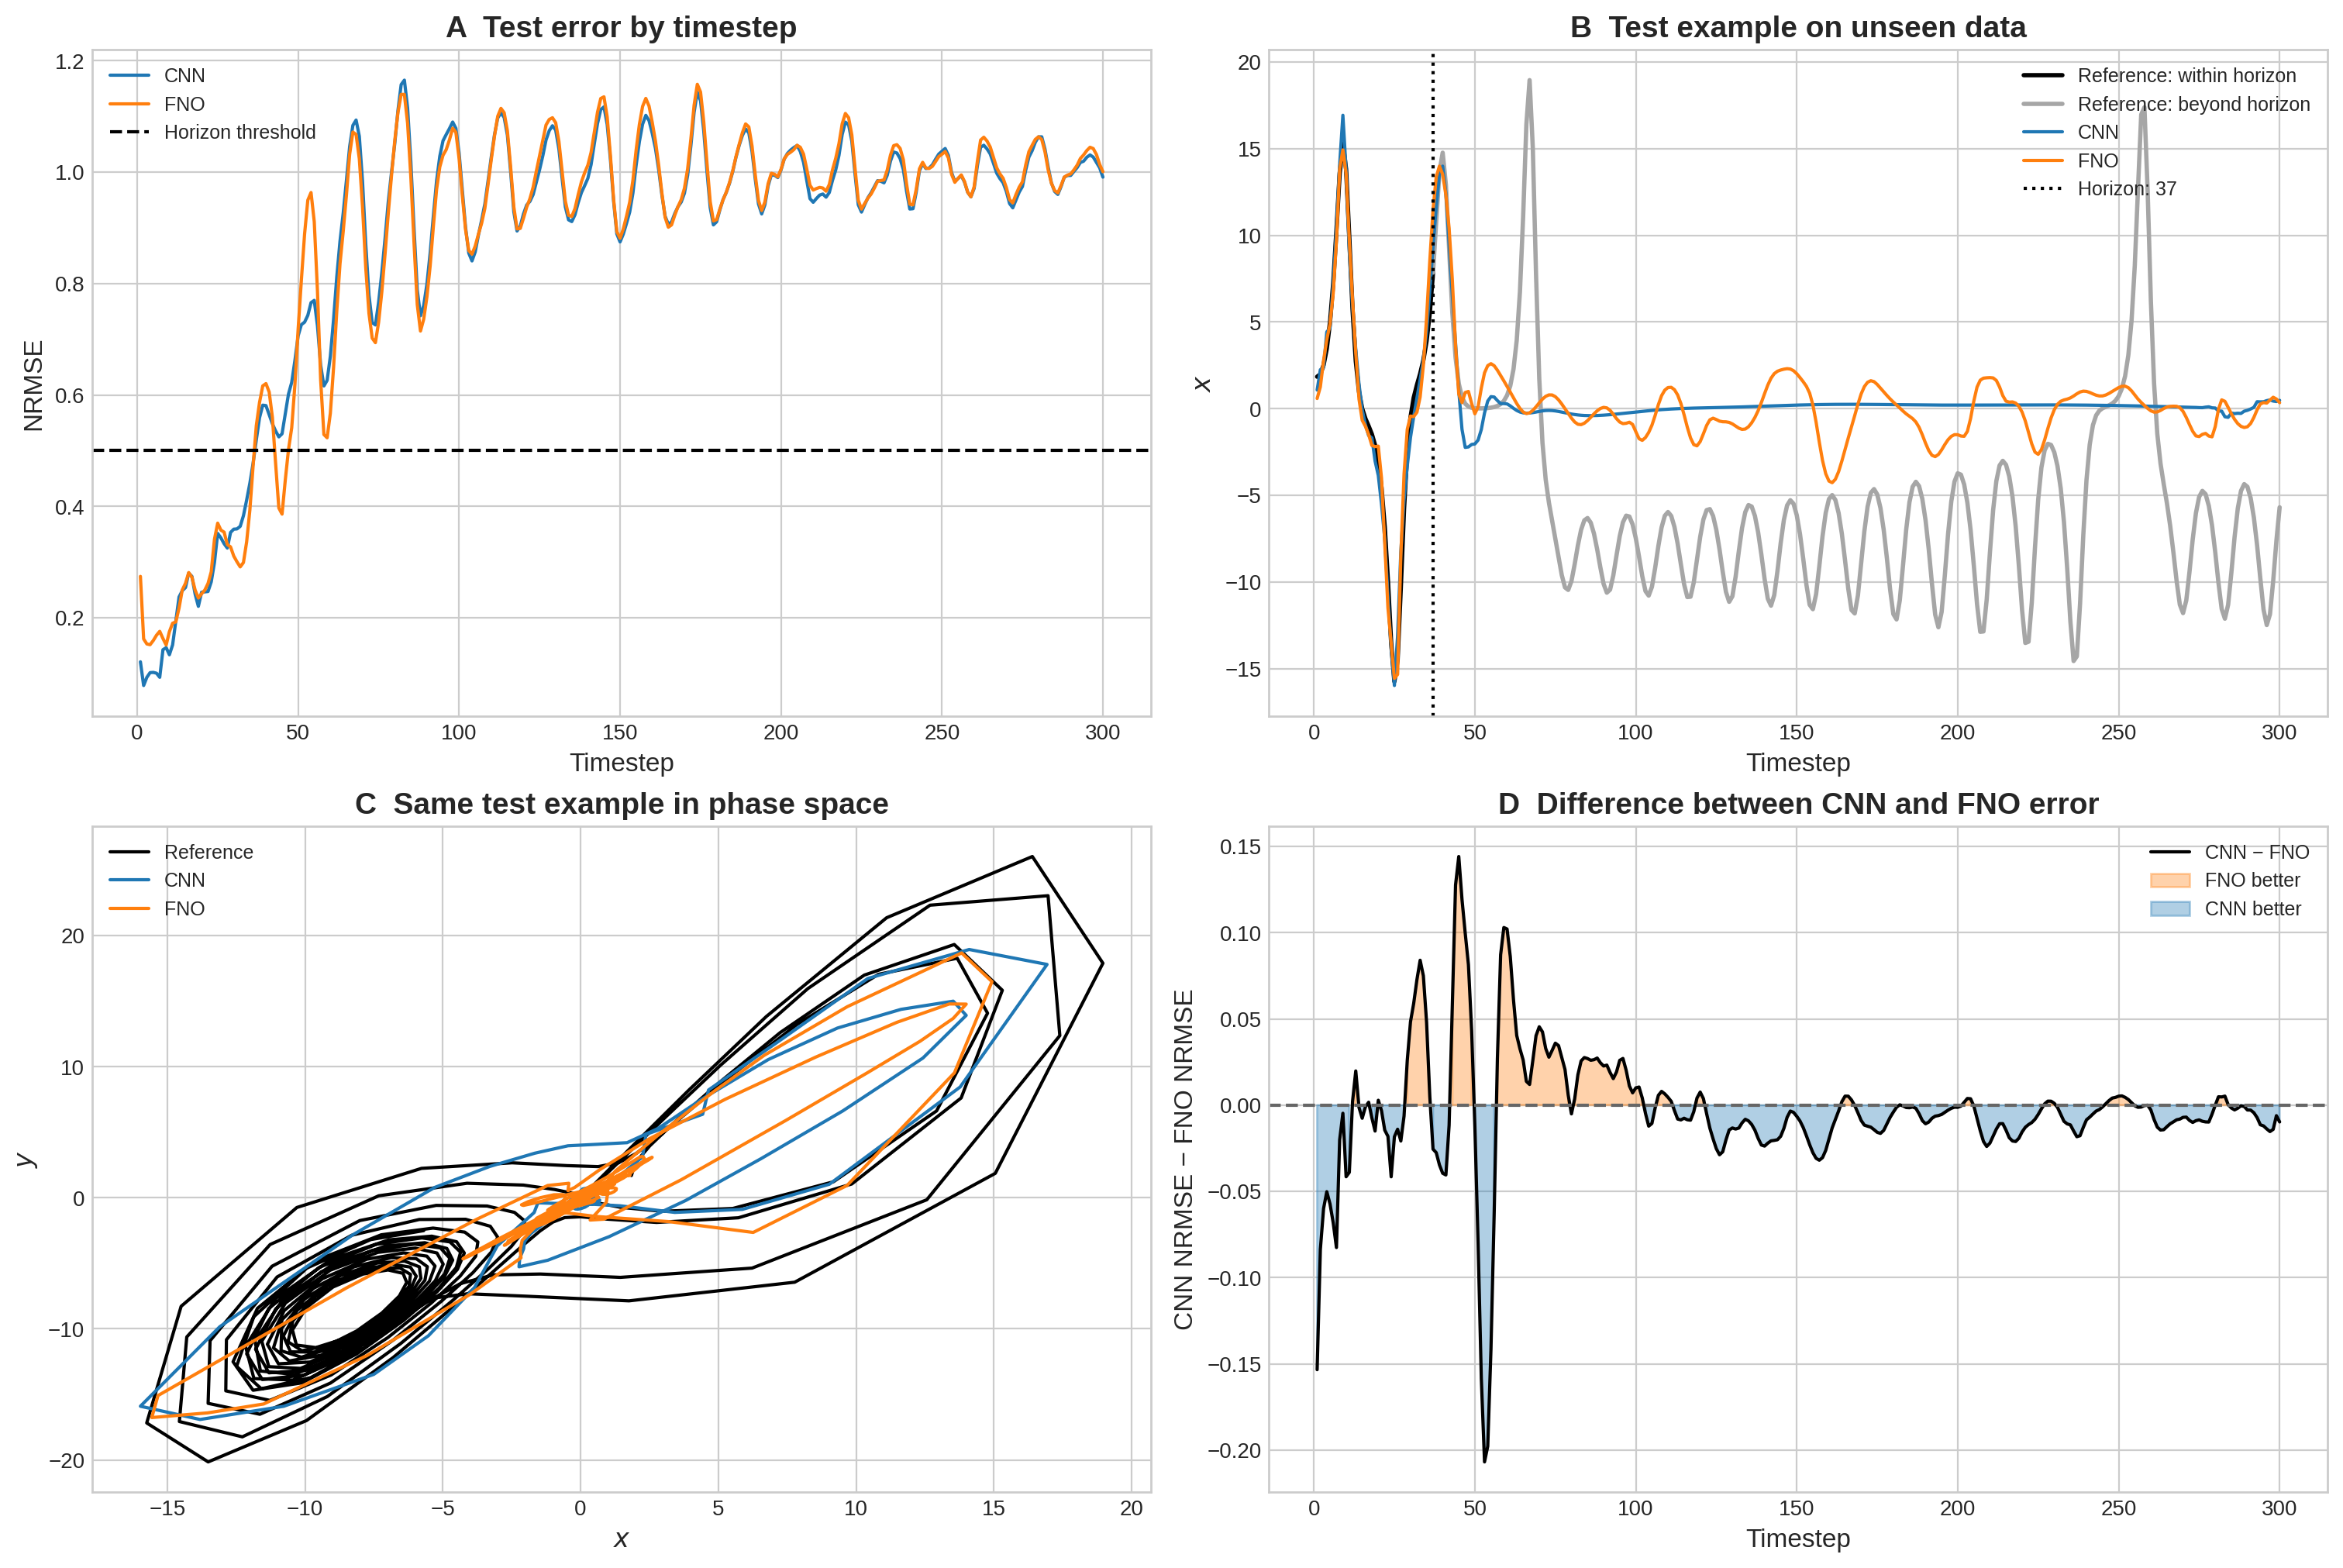

In [7]:
# show results in table and plots
def predict(model, inputs):
    model.eval()
    with torch.no_grad():
        return np.concatenate([
            model(torch.from_numpy(inputs[i:i+128]).to(device)).cpu().numpy()
            for i in range(0, len(inputs), 128)
        ])

predictions = {
    name: restore_targets(predict(model, test_input_standard))
    for name, model in trained_models.items()
}

def nrmse(pred, obs):
    return np.sqrt(np.mean(((pred - obs) / target_std) ** 2, axis=(0, 2)))

lead_errors = {
    name: nrmse(pred, test_targets)
    for name, pred in predictions.items()
}

windows = [('Short 1–50', 0, 50),
           ('Medium 51–150', 50, 150),
           ('Long 151–300', 150, 300)]

rows = []
for name, pred in predictions.items():
    crossing = np.flatnonzero(lead_errors[name] >= 0.5)
    row = {
        'Method': name,
        'Forecast horizon (timesteps)': int(crossing[0] + 1) if len(crossing) else 300
    }
    for label, start, end in windows:
        row[f'{label} NRMSE'] = np.sqrt(np.mean(
            ((pred[:, start:end] - test_targets[:, start:end]) / target_std) ** 2
        ))
    rows.append(row)

forecast_results = pd.DataFrame(rows)
display(forecast_results.round(4))

t = np.arange(1, 301)
i = 0
horizon = int(forecast_results['Forecast horizon (timesteps)'].max())
reference = test_targets[i, :, 0]

fig, axes = plt.subplots(2, 2, figsize=(15, 10), constrained_layout=True)
axA, axB, axC, axD = axes.ravel()

for name in ['CNN', 'FNO']:
    axA.plot(t, lead_errors[name], label=name)
axA.axhline(0.5, color='black', ls='--', label='Horizon threshold')
axA.set(title='A  Test error by timestep', xlabel='Timestep', ylabel='NRMSE')
axA.legend()

axB.plot(t[:horizon], reference[:horizon], color='black',
         lw=2, label='Reference: within horizon')
axB.plot(t[horizon-1:], reference[horizon-1:], color='0.65',
         lw=2, label='Reference: beyond horizon')
axB.plot(t, predictions['CNN'][i, :, 0], label='CNN')
axB.plot(t, predictions['FNO'][i, :, 0], label='FNO')
axB.axvline(horizon, color='black', ls=':', label=f'Horizon: {horizon}')
axB.set(title='B  Test example on unseen data', xlabel='Timestep', ylabel='$x$')
axB.legend(loc='upper right')

axC.plot(test_targets[i, :, 0], test_targets[i, :, 1],
         color='black', label='Reference')
for name in ['CNN', 'FNO']:
    axC.plot(predictions[name][i, :, 0],
             predictions[name][i, :, 1], label=name)
axC.set(title='C  Same test example in phase space', xlabel='$x$', ylabel='$y$')
axC.legend()

difference = lead_errors['CNN'] - lead_errors['FNO']
axD.plot(t, difference, color='black', label='CNN − FNO')
axD.axhline(0, color='0.4', ls='--')
axD.fill_between(t, 0, difference, where=difference >= 0,
                 color='tab:orange', alpha=0.35, label='FNO better')
axD.fill_between(t, 0, difference, where=difference < 0,
                 color='tab:blue', alpha=0.35, label='CNN better')
axD.set(title='D  Difference between CNN and FNO error',
        xlabel='Timestep', ylabel='CNN NRMSE − FNO NRMSE')
axD.legend(loc='upper right')

plt.show()

**Figure Interpretation:**

**Panel A** shows that CNN and FNO cross the error threshold at timesteps 37. FNO's error manages to get below 0.5 threshold around 40-50 timesteps but the error of CNN keep growing after timestep 37. Their error curve looks roughly the same after 70 timesteps. **In panel B**, the numerical reference changes from black to grey after the best forecast horizon (37 timesteps), making the unreliable part of the forecast explicit. CNN shows flat X predictions after 50 timesteps. However, FNO show meaningless but preiodic prediction. This comparison shows the differences of the two model natures. CNN's filters and MSE regression on physical space produce a nearly constant late forecast. FNO's low-frequency waves naturally continue producing smooth oscillations  **In panel C**, both models approximate the early phase-space path but fail to reproduce the reference trajectory’s later loops, indicating that neither model maintains the correct Lorenz dynamics over long forecasts. **Panel D** shows that performance differences are largest during the first 100 timesteps, while afterwards the errors become similar, with the mainly negative values indicating a small advantage for the CNN.

## 7. Does the learned forecast reproduce the butterfly effect?

Each test initial condition is paired with a second condition that differs by only `10⁻⁴`. The numerical reference, CNN and FNO all receive the same pairs. Panel A measures the median separation over all pairs, while panels B-D show one pair whose true trajectories clearly diverge. If the networks reproduce the butterfly effect, their paired predictions should separate in a similar way to the numerical reference.


,Predeclared butterfly test
Initial perturbation magnitude,0.0001
Truth separation threshold,1.0
Threshold reached within forecast,True
Comparison timestep,285


,Method,Median separation at truth horizon,Separation ratio to truth
0,Reference,1.0122,1.0
1,CNN,0.0000,0.0
2,FNO,0.0000,0.0


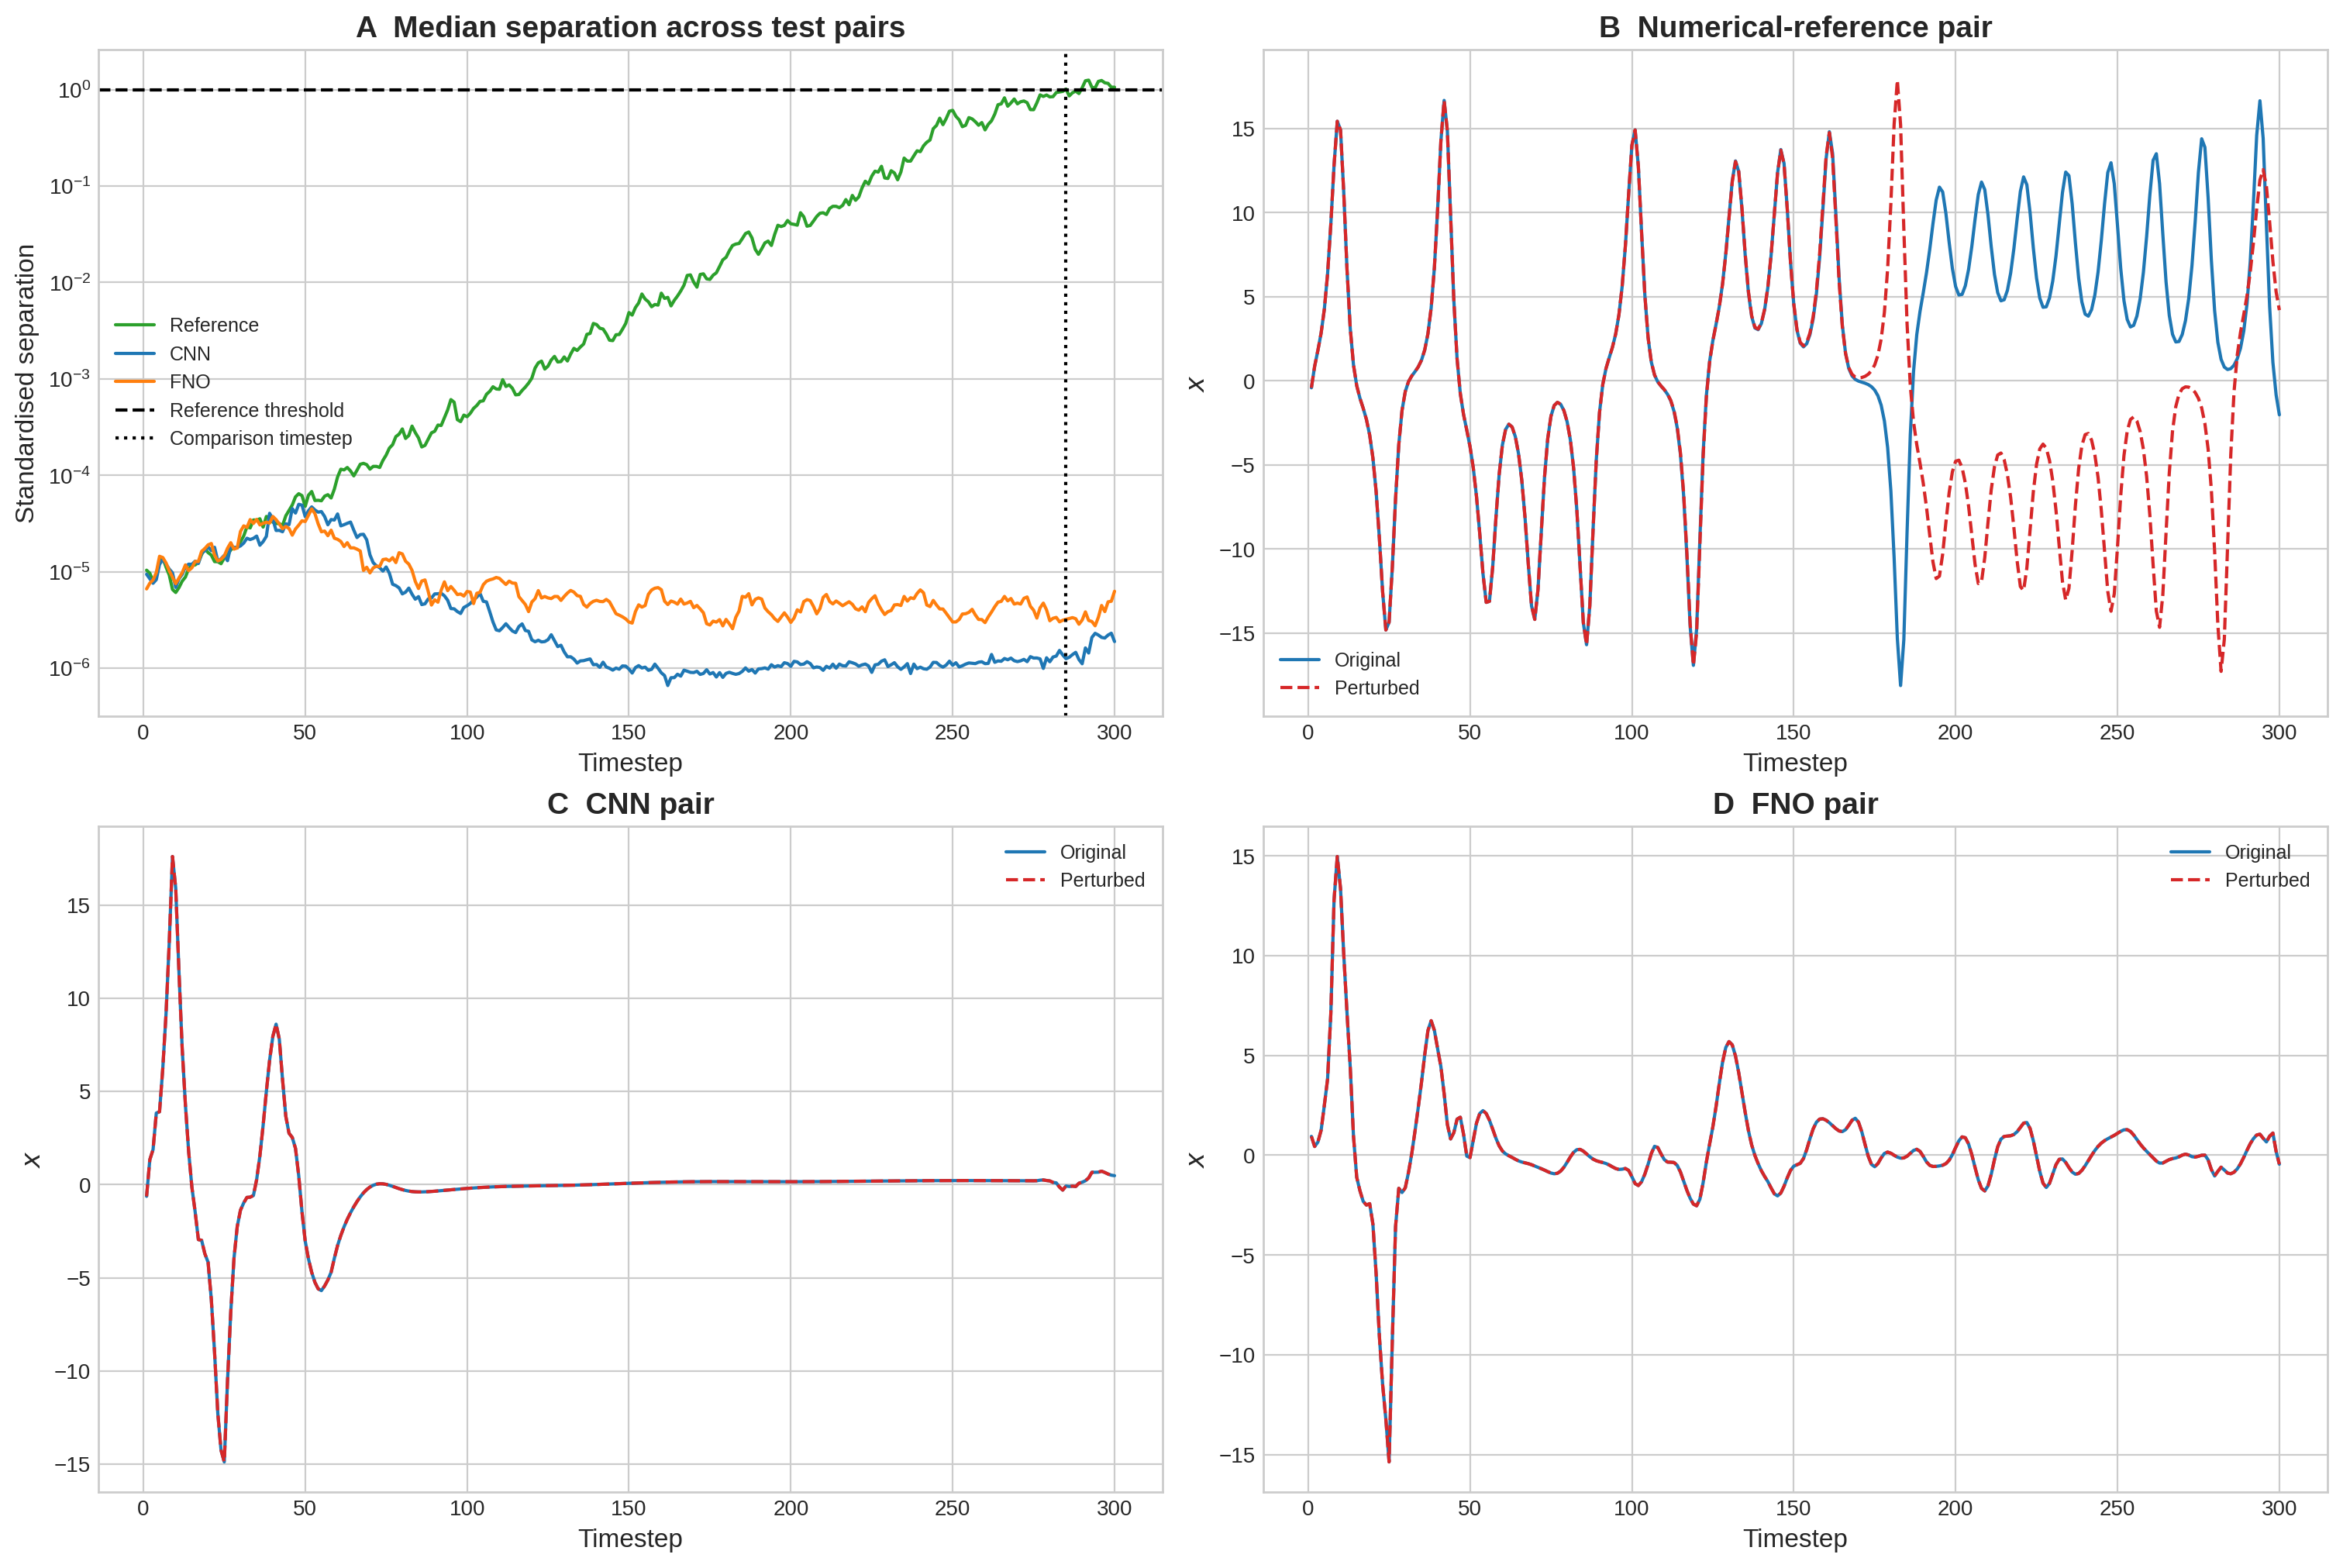

In [8]:
pair_count = min(64, TEST_SIZE)
perturbation_magnitude = 1e-4
pair_rng = np.random.default_rng(SEED + 100)
base_initial = test_initial[:pair_count].copy()
directions = pair_rng.normal(size=base_initial.shape)
directions /= np.linalg.norm(directions, axis=1, keepdims=True)
twin_initial = base_initial + perturbation_magnitude * directions

base_truth = test_targets[:pair_count]
twin_truth = generate_state_targets(twin_initial)[:, :, :2]


def standardized_separation(first, second):
    return np.linalg.norm((first - second) / target_std, axis=-1)


pair_trajectories = {'Reference': (base_truth, twin_truth)}
for family in ['CNN', 'FNO']:
    model = trained_models[family]
    base_prediction = restore_targets(predict(model, standardize_inputs(base_initial)))
    twin_prediction = restore_targets(predict(model, standardize_inputs(twin_initial)))
    pair_trajectories[family] = (base_prediction, twin_prediction)

separation_curves = {
    name: standardized_separation(first, second)
    for name, (first, second) in pair_trajectories.items()
}

median_separation = {
    name: np.median(values, axis=0) for name, values in separation_curves.items()
}
separation_threshold = 1.0
truth_crossings = np.flatnonzero(median_separation['Reference'] >= separation_threshold)
truth_threshold_reached = bool(len(truth_crossings))
butterfly_step = int(truth_crossings[0] + 1) if truth_threshold_reached else FORECAST_STEPS
butterfly_index = butterfly_step - 1

butterfly_rows = [{
    'Method': name,
    'Median separation at truth horizon': curve[butterfly_index],
    'Separation ratio to truth': curve[butterfly_index] / median_separation['Reference'][butterfly_index],
} for name, curve in median_separation.items()]
butterfly_results = pd.DataFrame(butterfly_rows)
display(pd.Series({
    'Initial perturbation magnitude': perturbation_magnitude,
    'Truth separation threshold': separation_threshold,
    'Threshold reached within forecast': truth_threshold_reached,
    'Comparison timestep': butterfly_step,
}, name='Predeclared butterfly test').to_frame())
display(butterfly_results.round(4))

pair_example = int(np.argmax(separation_curves['Reference'].max(axis=1)))
figure, axes = plt.subplots(2, 2, figsize=(15, 10), constrained_layout=True)

# Define explicit colors for the separation curves
color_map = {'Reference': 'tab:green', 'CNN': 'tab:blue', 'FNO': 'tab:orange'}

for name, curve in median_separation.items():
    axes[0, 0].semilogy(t, np.maximum(curve, 1e-12), label=name, color=color_map.get(name))
axes[0, 0].axhline(separation_threshold, color='black', linestyle='--', label='Reference threshold')
axes[0, 0].axvline(butterfly_step, color='black', linestyle=':', label='Comparison timestep')
axes[0, 0].set(
    title='A  Median separation across test pairs',
    xlabel='Timestep', ylabel='Standardised separation',
)
axes[0, 0].legend()

for axis, name, title in [
    (axes[0, 1], 'Reference', 'B  Numerical-reference pair'),
    (axes[1, 0], 'CNN', 'C  CNN pair'),
    (axes[1, 1], 'FNO', 'D  FNO pair'),
]:
    first, second = pair_trajectories[name]
    axis.plot(t, first[pair_example, :, 0], color='tab:blue', label='Original')
    axis.plot(t, second[pair_example, :, 0], color='tab:red', linestyle='--', label='Perturbed')
    axis.set(title=title, xlabel='Timestep', ylabel='$x$')
    axis.legend()
plt.show()

**Figure Interpretation:**

**Panel A (Median separation across test pairs):** The reference pairs exhibit natural error growth, reaching the separation threshold (dashed black line) at timestep 285. The median separation for the CNN and FNO models remains stagnant and orders of magnitude lower.
* **Panel B (Numerical-reference pair):** The selected original and perturbed reference trajectories visibly separate and diverge into distinct physical states as time progresses.
* **Panels C and D:** The CNN and FNO original and perturbed pairs remain almost perfectly identical throughout the entire horizon, failing to diverge.

At the comparison timestep, the CNN and FNO separation ratios to the reference are 0.00 and 0.00. This directly reproduces the type of failure reported by Selz and Craig (2023): ordinary forecast skill does not guarantee realistic growth of tiny initial differences.

## 8. Answer to the research question

While both the CNN and FNO provide useful short-range forecasts—with FNO achieving the lowest short-window NRMSE (0.373) and both models reaching a forecast horizon of 37 timesteps—neither produces accurate trajectories across the complete 300-timestep target. More importantly, both architectures fail to reproduce the chaotic divergence characteristic of the butterfly effect. The numerical reference reaches one standard deviation of median twin separation after 285 timesteps, whereas the CNN and FNO separation ratios remain at 0.00 at the comparison timestep (compared to an ideal ratio of 1). This confirms that a model can achieve reasonable short-range skill while still showing no butterfly effect in the long range, supporting the concerns raised by Selz and Craig (2023). This highlights a critical flaw in many contemporary deep learning surrogate studies, which frequently rely exclusively on pointwise error metrics like RMSE to claim success while ignoring whether the models actually preserve the fundamental chaotic and dynamic properties of the physical system.

Several limitations scope these findings. The experiment is deliberately low-dimensional and narrow: it relies on a single training seed per model and fixes z0=20 to simplify computation. Because initial conditions are drawn strictly from a [-15, 15]² square, the test measures regional interpolation rather than arbitrary-state generalization; future iterations should incorporate a varying z0 or an observation history.

### References

Bai, S., Kolter, J. Z. & Koltun, V. (2018). [An Empirical Evaluation of Generic Convolutional and Recurrent Networks for Sequence Modeling](https://arxiv.org/abs/1803.01271). *arXiv preprint arXiv:1803.01271*.

He, K., Zhang, X., Ren, S. & Sun, J. (2016). [Deep Residual Learning for Image Recognition](https://openaccess.thecvf.com/content_cvpr_2016/html/He_Deep_Residual_Learning_CVPR_2016_paper.html). *Proceedings of the IEEE Conference on Computer Vision and Pattern Recognition (CVPR)*, 770–778.

LeCun, Y., Bottou, L., Bengio, Y. & Haffner, P. (1998). [Gradient-Based Learning Applied to Document Recognition](https://doi.org/10.1109/5.726791). *Proceedings of the IEEE*, 86(11), 2278–2324.

Li, Z. *et al.* (2021). [Fourier Neural Operator for Parametric Partial Differential Equations](https://openreview.net/forum?id=c8P9NQVtmnO). *International Conference on Learning Representations*.

Lorenz, E. N. (1963). [Deterministic Nonperiodic Flow](https://doi.org/10.1175/1520-0469(1963)020%3C0130:DNF%3E2.0.CO;2). *Journal of the Atmospheric Sciences*, 20, 130–141.

Mak, J. (2026). *model_data_scrap.ipynb*. OCES 5303 course material, HKUST. The opening Lorenz-63 definition is adapted from this notebook.

Paszke, A. *et al.* (2019). [PyTorch: An Imperative Style, High-Performance Deep Learning Library](https://papers.neurips.cc/paper/9015-pytorch-an-imperative-style-high-performance-deep-learning-library). *Advances in Neural Information Processing Systems*, 32.

SciPy developers (2026). [`scipy.integrate.solve_ivp` documentation](https://docs.scipy.org/doc/scipy/reference/generated/scipy.integrate.solve_ivp.html).

Selz, T. & Craig, G. C. (2023). [Can Artificial Intelligence-Based Weather Prediction Models Simulate the Butterfly Effect?](https://doi.org/10.1029/2023GL105747). *Geophysical Research Letters*, 50, e2023GL105747.

Yu, F. & Koltun, V. (2016). [Multi-Scale Context Aggregation by Dilated Convolutions](https://arxiv.org/abs/1511.07122). *International Conference on Learning Representations (ICLR)*.
### AI assistance declaration

OpenAI Codex was used to help structure the first draft of the notebook, review code and refine prose. The author remains responsible for the scientific design, source checking, execution, interpretation and submitted work.
